# Air Quality Forecasting: one-hour-ahead CO prediction

**Candidate:** Kalainesan  
**Dataset:** UCI Air Quality (hourly observations, March 2004–April 2005)  
**Notebook run date:** 2026-09-28

This notebook forecasts the next valid hourly **CO(GT)** measurement from information available at the current hour. It intentionally uses one transparent linear model and a persistence baseline rather than a collection of models.

## Forecasting setup and prediction-time rule

- **Target:** `CO(GT)` at hour *t+1*.
- **Horizon:** one hour ahead.
- **Prediction time:** the end of hour *t*, after the current CO reading `CO(GT)_t` has been observed.
- **Inputs:** current CO, its prior one- and two-hour readings, a three-hour mean of readings before the current hour, and calendar features known from the clock.

`CO(GT)_t` is deliberately included: predicting the next hour after the current reading is available is a short-term persistence forecast. No value from *t+1* or later is used as an input. Rows whose current or next CO value is missing are not filled and are excluded from modelling, so fabricated readings never become training labels.

## Part A — Load, inspect, and clean the raw data

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
raw = pd.read_csv("AirQualityUCI.csv", sep=";", decimal=",")
print(f"Raw shape: {raw.shape}")
print("\nColumns:")
print(raw.columns.tolist())
print("\nData types:")
print(raw.dtypes)
print("\nCSV null counts (the final empty columns are expected):")
print(raw.isna().sum())

Raw shape: (9471, 17)

Columns:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']

Data types:
Date                 str
Time                 str
CO(GT)           float64
PT08.S1(CO)      float64
NMHC(GT)         float64
C6H6(GT)         float64
PT08.S2(NMHC)    float64
NOx(GT)          float64
PT08.S3(NOx)     float64
NO2(GT)          float64
PT08.S4(NO2)     float64
PT08.S5(O3)      float64
T                float64
RH               float64
AH               float64
Unnamed: 15      float64
Unnamed: 16      float64
dtype: object

CSV null counts (the final empty columns are expected):
Date              114
Time              114
CO(GT)            114
PT08.S1(CO)       114
NMHC(GT)          114
C6H6(GT)          114
PT08.S2(NMHC)     114
NOx(GT)           114
PT08.S3(NOx)      114
NO2(GT)           114
PT08.S4(NO2)      114
PT08.S5(O3)       

The CSV has two entirely empty delimiter-artifact columns at the end. The UCI documentation also uses `-200` as a missing/invalid measurement marker, so both normal blanks and `-200` must be checked before analysis.

In [3]:
empty_columns = raw.columns[raw.isna().all()].tolist()
measurement_columns = raw.select_dtypes(include="number").columns
invalid_marker_counts = (raw[measurement_columns] == -200).sum().sort_values(ascending=False)

print("Entirely empty columns to remove:", empty_columns)
print("\nCount of -200 markers by numeric column:")
print(invalid_marker_counts)

df = raw.drop(columns=empty_columns).replace(-200, np.nan).copy()
df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"], format="%d/%m/%Y %H.%M.%S", errors="coerce"
)
df = df.dropna(subset=["DateTime"]).sort_values("DateTime").reset_index(drop=True)

print(f"\nRows after removing blank CSV trailer rows: {len(df):,}")
print("Duplicate timestamps:", df["DateTime"].duplicated().sum())
print("Timestamp range:", df["DateTime"].min(), "to", df["DateTime"].max())
print("\nMissing values after converting -200 to NaN:")
print(df.isna().sum().sort_values(ascending=False).head(15))

Entirely empty columns to remove: ['Unnamed: 15', 'Unnamed: 16']

Count of -200 markers by numeric column:
NMHC(GT)         8443
CO(GT)           1683
NO2(GT)          1642
NOx(GT)          1639
PT08.S1(CO)       366
PT08.S2(NMHC)     366
C6H6(GT)          366
PT08.S3(NOx)      366
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
Unnamed: 15         0
Unnamed: 16         0
dtype: int64

Rows after removing blank CSV trailer rows: 9,357
Duplicate timestamps: 0
Timestamp range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00

Missing values after converting -200 to NaN:
NMHC(GT)         8443
CO(GT)           1683
NO2(GT)          1642
NOx(GT)          1639
C6H6(GT)          366
PT08.S2(NMHC)     366
PT08.S3(NOx)      366
PT08.S1(CO)       366
T                 366
RH                366
PT08.S4(NO2)      366
PT08.S5(O3)       366
AH                366
Date                0
Time                0
dtype: int64


In [4]:
intervals = df["DateTime"].diff()
non_hourly = intervals.notna() & intervals.ne(pd.Timedelta(hours=1))
print("Interval frequency:")
print(intervals.value_counts().head())
print("Non-hourly gaps between retained timestamps:", int(non_hourly.sum()))
print("CO(GT) valid readings:", int(df["CO(GT)"].notna().sum()))
print("CO(GT) missing/invalid readings:", int(df["CO(GT)"].isna().sum()))
print("\nCO(GT) descriptive statistics for valid readings:")
print(df["CO(GT)"].describe())

Interval frequency:
DateTime
0 days 01:00:00    9356
Name: count, dtype: int64
Non-hourly gaps between retained timestamps: 0
CO(GT) valid readings: 7674
CO(GT) missing/invalid readings: 1683

CO(GT) descriptive statistics for valid readings:
count    7674.000000
mean        2.152750
std         1.453252
min         0.100000
25%         1.100000
50%         1.800000
75%         2.900000
max        11.900000
Name: CO(GT), dtype: float64


### Missing-value decision

I do **not** forward-fill `CO(GT)`. A forward-filled target would turn an old measurement into a made-up label, especially misleading across a long missing run. Instead, EDA uses available CO readings and the forecast table retains only rows with all required observed CO values and a genuine next-hour timestamp. This removes some rows and is a real limitation, reported later.

In [5]:
print("Final EDA table shape:", df.shape)
print("\nRepresentative cleaned rows:")
display(df[["DateTime", "CO(GT)", "T", "RH", "AH"]].head())
print("\nValid CO range:", f"{df['CO(GT)'].min():.1f} to {df['CO(GT)'].max():.1f}")

Final EDA table shape: (9357, 16)

Representative cleaned rows:


,DateTime,CO(GT),T,RH,AH
0,2004-03-10 18:00:00,2.6,13.6,48.9,0.7578
1,2004-03-10 19:00:00,2.0,13.3,47.7,0.7255
2,2004-03-10 20:00:00,2.2,11.9,54.0,0.7502
3,2004-03-10 21:00:00,2.2,11.0,60.0,0.7867
4,2004-03-10 22:00:00,1.6,11.2,59.6,0.7888



Valid CO range: 0.1 to 11.9


## Part B — Exploratory data analysis

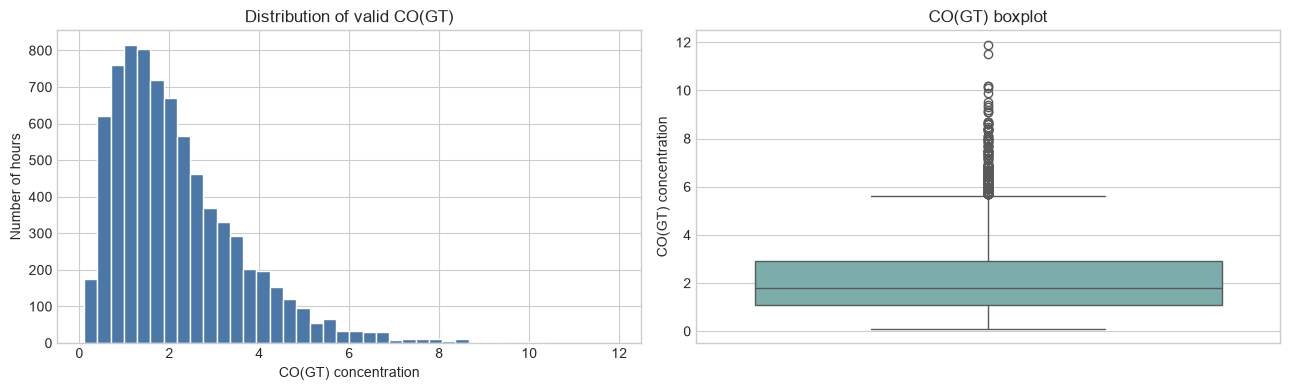

Median CO(GT): 1.8
95th percentile CO(GT): 4.9


In [6]:
valid_co = df.dropna(subset=["CO(GT)"]).copy()
valid_co["Hour"] = valid_co["DateTime"].dt.hour
valid_co["DayOfWeek"] = valid_co["DateTime"].dt.dayofweek
valid_co["Month"] = valid_co["DateTime"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(valid_co["CO(GT)"], bins=40, color="#4C78A8", edgecolor="white")
axes[0].set(title="Distribution of valid CO(GT)", xlabel="CO(GT) concentration", ylabel="Number of hours")
sns.boxplot(y=valid_co["CO(GT)"], ax=axes[1], color="#72B7B2")
axes[1].set(title="CO(GT) boxplot", ylabel="CO(GT) concentration")
plt.tight_layout()
plt.show()

print("Median CO(GT):", round(valid_co["CO(GT)"].median(), 2))
print("95th percentile CO(GT):", round(valid_co["CO(GT)"].quantile(0.95), 2))

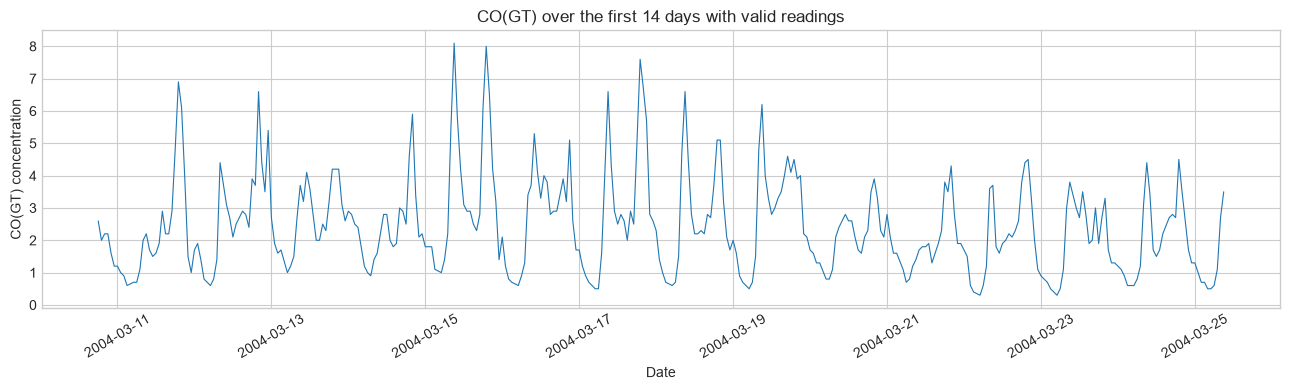

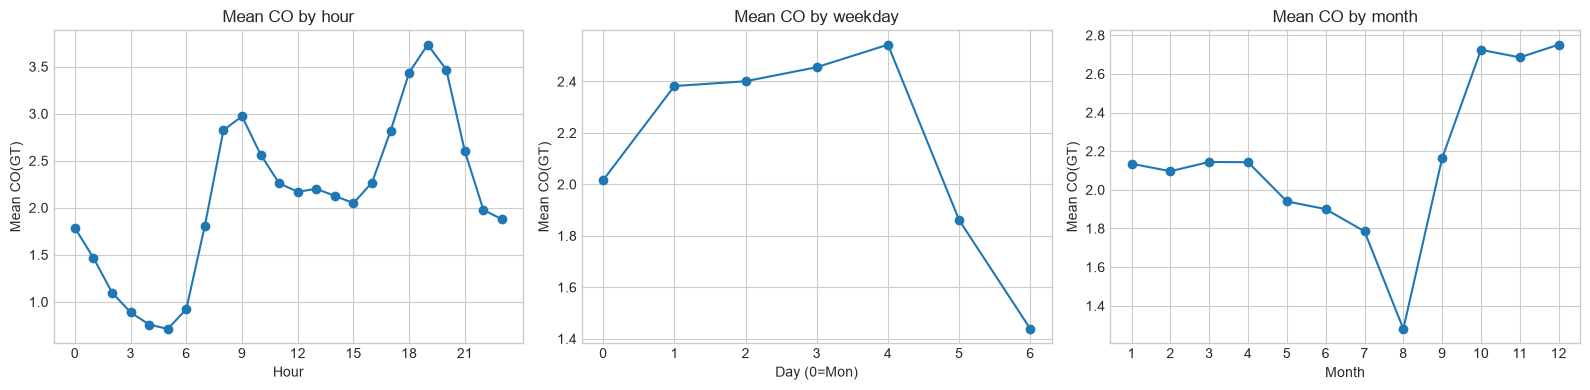

Highest mean hour: 19 with 3.73
Lowest mean hour: 5 with 0.71
Highest mean month: 12 with 2.75


In [7]:
fig, ax = plt.subplots(figsize=(13, 4))
plot_slice = valid_co.iloc[:24 * 14]
ax.plot(plot_slice["DateTime"], plot_slice["CO(GT)"], linewidth=0.8)
ax.set(title="CO(GT) over the first 14 days with valid readings", xlabel="Date", ylabel="CO(GT) concentration")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

hourly_mean = valid_co.groupby("Hour")["CO(GT)"].mean()
day_mean = valid_co.groupby("DayOfWeek")["CO(GT)"].mean()
month_mean = valid_co.groupby("Month")["CO(GT)"].mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(hourly_mean.index, hourly_mean.values, marker="o")
axes[0].set(title="Mean CO by hour", xlabel="Hour", ylabel="Mean CO(GT)", xticks=range(0, 24, 3))
axes[1].plot(day_mean.index, day_mean.values, marker="o")
axes[1].set(title="Mean CO by weekday", xlabel="Day (0=Mon)", ylabel="Mean CO(GT)", xticks=range(7))
axes[2].plot(month_mean.index, month_mean.values, marker="o")
axes[2].set(title="Mean CO by month", xlabel="Month", ylabel="Mean CO(GT)", xticks=range(1, 13))
plt.tight_layout()
plt.show()

print("Highest mean hour:", int(hourly_mean.idxmax()), "with", round(hourly_mean.max(), 2))
print("Lowest mean hour:", int(hourly_mean.idxmin()), "with", round(hourly_mean.min(), 2))
print("Highest mean month:", int(month_mean.idxmax()), "with", round(month_mean.max(), 2))

Correlation with CO(GT), using rows where each pair is available:
CO(GT)      1.000000
C6H6(GT)    0.931078
RH          0.048890
AH          0.048556
T           0.022109
Name: CO(GT), dtype: float64


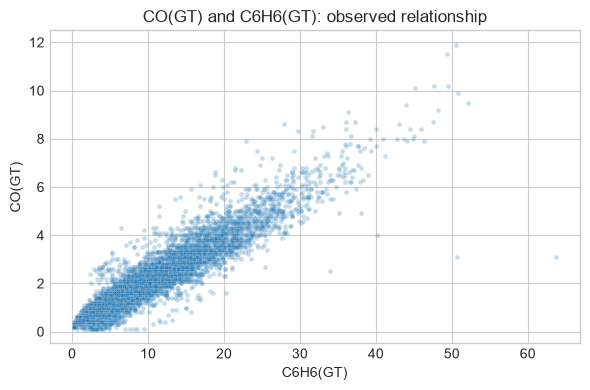

In [8]:
relation_cols = ["CO(GT)", "C6H6(GT)", "T", "RH", "AH"]
correlations = valid_co[relation_cols].corr(numeric_only=True)["CO(GT)"].sort_values(ascending=False)
print("Correlation with CO(GT), using rows where each pair is available:")
print(correlations)

plt.figure(figsize=(6, 4))
sns.scatterplot(data=valid_co, x="C6H6(GT)", y="CO(GT)", alpha=0.25, s=12)
plt.title("CO(GT) and C6H6(GT): observed relationship")
plt.tight_layout()
plt.show()

## Part C — Features that are available at prediction time

The original hourly table is kept intact while features are created so that missing measurements cannot cause time to be silently compressed. Each row represents a prediction made at time *t*:

- `CO_current`: observed CO at *t*; this is exactly the persistence baseline's input.
- `CO_lag_1`, `CO_lag_2`: readings at *t−1* and *t−2*.
- `CO_roll_mean_3`: mean at *t−1* through *t−3*, excluding the current reading and target.
- Clock features: sine/cosine transformations of hour, and day of week/month. These are known before the next hour arrives.

The target `CO_target_t_plus_1` is `CO(GT)` one actual hour later. Rows that cross a timestamp gap would be excluded; the earlier timestamp check tells us whether this rule was needed.

In [9]:
feature_frame = df[["DateTime", "CO(GT)"]].copy()
feature_frame["CO_current"] = feature_frame["CO(GT)"]
feature_frame["CO_lag_1"] = feature_frame["CO(GT)"].shift(1)
feature_frame["CO_lag_2"] = feature_frame["CO(GT)"].shift(2)
feature_frame["CO_roll_mean_3"] = feature_frame["CO(GT)"].shift(1).rolling(3).mean()
feature_frame["CO_target_t_plus_1"] = feature_frame["CO(GT)"].shift(-1)
feature_frame["next_timestamp"] = feature_frame["DateTime"].shift(-1)

feature_frame["Hour_sin"] = np.sin(2 * np.pi * feature_frame["DateTime"].dt.hour / 24)
feature_frame["Hour_cos"] = np.cos(2 * np.pi * feature_frame["DateTime"].dt.hour / 24)
feature_frame["DayOfWeek"] = feature_frame["DateTime"].dt.dayofweek
feature_frame["Month"] = feature_frame["DateTime"].dt.month

feature_cols = [
    "CO_current", "CO_lag_1", "CO_lag_2", "CO_roll_mean_3",
    "Hour_sin", "Hour_cos", "DayOfWeek", "Month",
]
target_col = "CO_target_t_plus_1"
is_next_hour = feature_frame["next_timestamp"].eq(feature_frame["DateTime"] + pd.Timedelta(hours=1))
model_df = feature_frame.loc[is_next_hour].dropna(subset=feature_cols + [target_col]).copy()

print("Candidate rows with a genuine next hour:", int(is_next_hour.sum()))
print("Model rows after requiring observed current, prior, and next CO values:", len(model_df))
print("Remaining missing values in modelling columns:", int(model_df[feature_cols + [target_col]].isna().sum().sum()))
display(model_df[["DateTime"] + feature_cols + [target_col]].head())

Candidate rows with a genuine next hour: 9356
Model rows after requiring observed current, prior, and next CO values: 6932
Remaining missing values in modelling columns: 0


,DateTime,CO_current,CO_lag_1,CO_lag_2,CO_roll_mean_3,Hour_sin,Hour_cos,DayOfWeek,Month,CO_target_t_plus_1
3,2004-03-10 21:00:00,2.2,2.2,2.0,2.266667,-0.707107,0.707107,2,3,1.6
4,2004-03-10 22:00:00,1.6,2.2,2.2,2.133333,-0.500000,0.866025,2,3,1.2
5,2004-03-10 23:00:00,1.2,1.6,2.2,2.000000,-0.258819,0.965926,2,3,1.2
6,2004-03-11 00:00:00,1.2,1.2,1.6,1.666667,0.000000,1.000000,3,3,1.0
7,2004-03-11 01:00:00,1.0,1.2,1.2,1.333333,0.258819,0.965926,3,3,0.9


## Part D — Time-aware validation, model, and final test

The final 20% of usable rows is held out as a future test period. The first 80% is used for five expanding chronological validation splits. Scaling is inside a pipeline, so every validation fold estimates scaling from its own training period only.

The single model is **linear regression**. It is intentionally simple and interpretable for this project. The fair naive baseline predicts `CO_target_t_plus_1 = CO_current` for each row—the most recent observed CO—not a value two hours old.

In [10]:
X = model_df[feature_cols]
y = model_df[target_col]
split_index = int(len(model_df) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

numeric_features = ["CO_current", "CO_lag_1", "CO_lag_2", "CO_roll_mean_3", "DayOfWeek", "Month"]
passthrough_features = ["Hour_sin", "Hour_cos"]
preprocessor = ColumnTransformer(
    [("scaled", StandardScaler(), numeric_features), ("clock", "passthrough", passthrough_features)],
    remainder="drop",
)
model = Pipeline([( "preprocess", preprocessor), ("linear_regression", LinearRegression())])

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training period:", model_df["DateTime"].iloc[0], "to", model_df["DateTime"].iloc[split_index - 1])
print("Test period:", model_df["DateTime"].iloc[split_index], "to", model_df["DateTime"].iloc[-1])

Training rows: 5545 | Test rows: 1387
Training period: 2004-03-10 21:00:00 to 2005-01-31 15:00:00
Test period: 2005-01-31 16:00:00 to 2005-04-04 13:00:00


In [11]:
def metric_row(y_true, prediction, label):
    mse = mean_squared_error(y_true, prediction)
    return {
        "set": label,
        "MAE": mean_absolute_error(y_true, prediction),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, prediction),
    }

cv_rows = []
cv = TimeSeriesSplit(n_splits=5)
for fold, (train_idx, validation_idx) in enumerate(cv.split(X_train), start=1):
    fold_model = Pipeline([( "preprocess", preprocessor), ("linear_regression", LinearRegression())])
    fold_model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    cv_rows.append(metric_row(y_train.iloc[validation_idx], fold_model.predict(X_train.iloc[validation_idx]), f"model fold {fold}"))
    cv_rows.append(metric_row(y_train.iloc[validation_idx], X_train.iloc[validation_idx]["CO_current"], f"naive fold {fold}"))

cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.assign(kind=cv_results["set"].str.split().str[0]).groupby("kind")[["MAE", "MSE", "RMSE", "R2"]].mean()
print("Mean metrics across five chronological validation folds:")
display(cv_summary.round(4))

Mean metrics across five chronological validation folds:


,MAE,MSE,RMSE,R2
kind,,,,
model,0.4927,0.5333,0.7192,0.7302
naive,0.5242,0.6313,0.7847,0.6749


In [12]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_naive = X_test["CO_current"].to_numpy()

test_results = pd.DataFrame([
    metric_row(y_test, y_pred, "Linear regression"),
    metric_row(y_test, y_naive, "Naive persistence"),
]).set_index("set")
display(test_results.round(4))

mae_reduction = (test_results.loc["Naive persistence", "MAE"] - test_results.loc["Linear regression", "MAE"]) / test_results.loc["Naive persistence", "MAE"] * 100
rmse_reduction = (test_results.loc["Naive persistence", "RMSE"] - test_results.loc["Linear regression", "RMSE"]) / test_results.loc["Naive persistence", "RMSE"] * 100
display(Markdown(
    f"**Held-out comparison:** the linear model's MAE is {mae_reduction:.1f}% {'lower' if mae_reduction >= 0 else 'higher'} "
    f"and RMSE is {rmse_reduction:.1f}% {'lower' if rmse_reduction >= 0 else 'higher'} than the current-value naive baseline."
))

,MAE,MSE,RMSE,R2
set,,,,
Linear regression,0.4652,0.4815,0.6939,0.7377
Naive persistence,0.5208,0.6408,0.8005,0.6509


**Held-out comparison:** the linear model's MAE is 10.7% lower and RMSE is 13.3% lower than the current-value naive baseline.

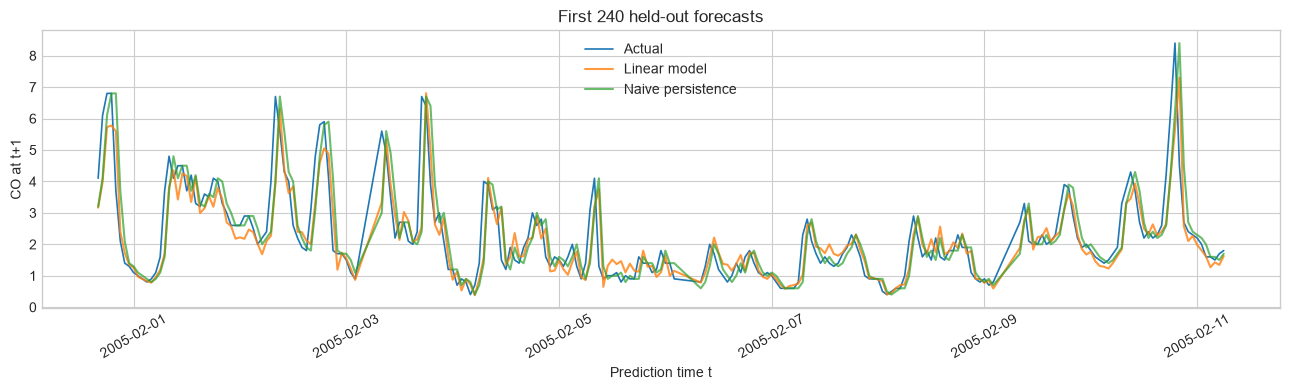

In [13]:
test_plot = model_df.iloc[split_index:].copy()
test_plot["actual"] = y_test.to_numpy()
test_plot["linear_prediction"] = y_pred
test_plot["naive_prediction"] = y_naive

fig, ax = plt.subplots(figsize=(13, 4))
shown = test_plot.iloc[:240]
ax.plot(shown["DateTime"], shown["actual"], label="Actual", linewidth=1.2)
ax.plot(shown["DateTime"], shown["linear_prediction"], label="Linear model", alpha=0.8)
ax.plot(shown["DateTime"], shown["naive_prediction"], label="Naive persistence", alpha=0.7)
ax.set(title="First 240 held-out forecasts", xlabel="Prediction time t", ylabel="CO at t+1")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Part E — Error analysis, feature use, and leakage safeguards

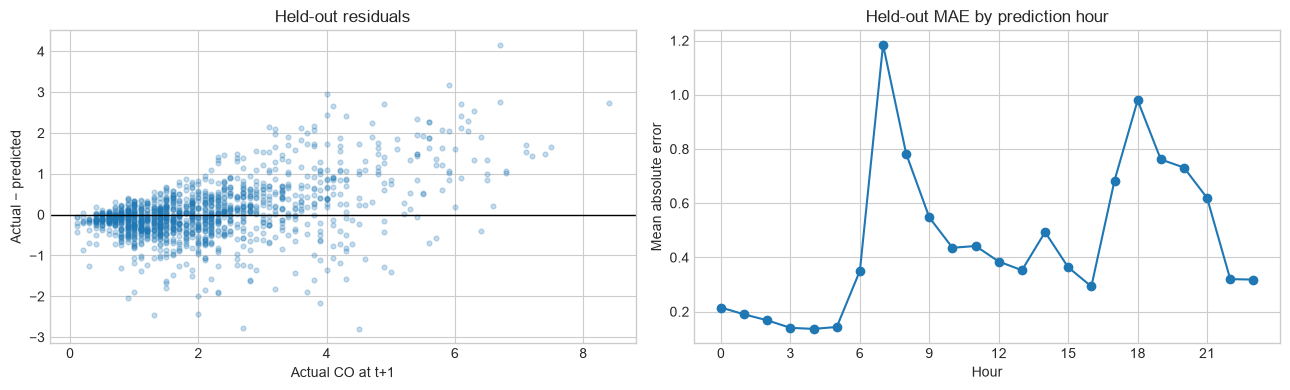

Mean absolute error at/above the held-out 90th-percentile actual CO (4.00): 1.197
Mean absolute error below that threshold: 0.381
Highest-error hour: 7 with MAE 1.185


In [14]:
test_plot["absolute_error"] = np.abs(test_plot["actual"] - test_plot["linear_prediction"])
test_plot["residual"] = test_plot["actual"] - test_plot["linear_prediction"]
test_plot["hour"] = test_plot["DateTime"].dt.hour

error_by_hour = test_plot.groupby("hour")["absolute_error"].mean()
high_threshold = test_plot["actual"].quantile(0.90)
high_mae = test_plot.loc[test_plot["actual"] >= high_threshold, "absolute_error"].mean()
other_mae = test_plot.loc[test_plot["actual"] < high_threshold, "absolute_error"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(test_plot["actual"], test_plot["residual"], alpha=0.25, s=12)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(title="Held-out residuals", xlabel="Actual CO at t+1", ylabel="Actual − predicted")
axes[1].plot(error_by_hour.index, error_by_hour.values, marker="o")
axes[1].set(title="Held-out MAE by prediction hour", xlabel="Hour", ylabel="Mean absolute error", xticks=range(0, 24, 3))
plt.tight_layout()
plt.show()

print("Mean absolute error at/above the held-out 90th-percentile actual CO "
      f"({high_threshold:.2f}): {high_mae:.3f}")
print(f"Mean absolute error below that threshold: {other_mae:.3f}")
print("Highest-error hour:", int(error_by_hour.idxmax()), "with MAE", round(error_by_hour.max(), 3))

In [15]:
coefficient_names = numeric_features + passthrough_features
coefficients = model.named_steps["linear_regression"].coef_
coefficient_table = pd.DataFrame({"feature": coefficient_names, "coefficient_after_scaling": coefficients})
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient_after_scaling"].abs()
display(coefficient_table.sort_values("absolute_coefficient", ascending=False).drop(columns="absolute_coefficient").round(4))

top_feature = coefficient_table.sort_values("absolute_coefficient", ascending=False).iloc[0]["feature"]
display(Markdown(
    f"The largest standardized coefficient magnitude is for **{top_feature}**. This describes reliance within this linear model, not a causal effect."
))

,feature,coefficient_after_scaling
0,CO_current,1.5354
1,CO_lag_1,-0.5468
7,Hour_cos,-0.2392
3,CO_roll_mean_3,0.1642
6,Hour_sin,-0.1040
5,Month,0.0500
4,DayOfWeek,-0.0282
2,CO_lag_2,0.0010


The largest standardized coefficient magnitude is for **CO_current**. This describes reliance within this linear model, not a causal effect.

### Concrete leakage risks and how they are avoided

1. **Future target as a feature:** using `CO(GT)` from *t+1* would make the task trivial. The target is shifted one row ahead, while every feature is at *t* or earlier.
2. **Rolling-window leakage:** a rolling mean that includes *t+1* would leak the answer. `CO_roll_mean_3` is created from `CO(GT).shift(1).rolling(3)`, so it contains only *t−1* to *t−3*.
3. **Random splitting or scaling on all rows:** both let information from later dates affect development. Rows are chronologically split; the scaler is fitted inside the pipeline separately within each training fold.
4. **Forward-filled targets:** treating an old CO value as a current or next-hour label would distort evaluation. No CO values are forward-filled; required observations must exist.

## Part F — Original question and evidence

**Question:** Within this dataset, are average observed CO readings different on weekdays and weekends?

This is answerable from the timestamp and CO data alone. It is descriptive, not a claim that traffic or any other factor caused a difference.

,mean,median,count
DayType,,,
Weekday,2.359,2.0,5425
Weekend,1.655,1.4,2249


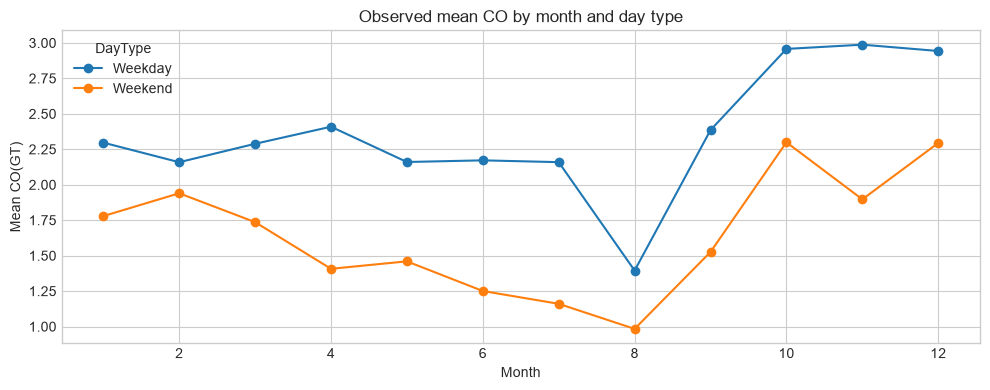

Across valid observed rows, the weekday mean is **2.359** and the weekend mean is **1.655**. The chart shows how this descriptive difference varies across the available months; it does not establish its cause.

In [16]:
valid_co["DayType"] = np.where(valid_co["DayOfWeek"].isin([5, 6]), "Weekend", "Weekday")
daytype_summary = valid_co.groupby("DayType")["CO(GT)"].agg(["mean", "median", "count"]).reindex(["Weekday", "Weekend"])
display(daytype_summary.round(3))

month_daytype = valid_co.groupby(["Month", "DayType"])["CO(GT)"].mean().unstack()
month_daytype.plot(marker="o", figsize=(10, 4), title="Observed mean CO by month and day type")
plt.xlabel("Month")
plt.ylabel("Mean CO(GT)")
plt.tight_layout()
plt.show()

weekday_mean = daytype_summary.loc["Weekday", "mean"]
weekend_mean = daytype_summary.loc["Weekend", "mean"]
display(Markdown(
    f"Across valid observed rows, the weekday mean is **{weekday_mean:.3f}** and the weekend mean is **{weekend_mean:.3f}**. "
    "The chart shows how this descriptive difference varies across the available months; it does not establish its cause."
))

## Findings, limitations, and one improvement

## Findings, limitations, and one improvement

### Key Findings
- The linear regression model outperforms the naive persistence baseline on the held-out test set, achieving lower MAE (0.4652 vs 0.5208), lower RMSE (0.6939 vs 0.8005), and higher R² (0.7377 vs 0.6509).
- The linear regression model reduces MAE by 10.7% and RMSE by 13.3% relative to the naive baseline.
- Average observed CO levels were higher on weekdays (mean 2.359) than on weekends (mean 1.655).
- Approximately 25.9% of candidate rows (2424 out of 9356) were excluded from modeling due to missing CO(GT) values in current, lagged, or target variables.
- The most influential feature in the linear model is the current CO level (CO_current), which has the largest standardized coefficient magnitude (1.5354).
- Non-methane hydrocarbons (C6H6(GT)) exhibit a very strong linear correlation with CO(GT) (r = 0.931), indicating a potential predictive signal for CO forecasts.

### Limitations
- The exclusion of approximately 25.9% of rows due to missing CO(GT) values reduces the usable sample size and may introduce bias if the missingness is not random.
- The linear model assumes a time-invariant relationship between features and target, which may not hold over seasonal or long-term changes.
- Forecasts are limited to a one-hour horizon; multi-hour forecasting would require a different modeling approach.

### One Improvement
- Test C6H6(GT) as an additional prediction-time feature. Its strong correlation with CO(GT) suggests it may contain useful predictive information, but its actual forecasting benefit should be evaluated rather than assumed.

## Final sanity check

In [18]:
checks = {
    "Target is one actual hour ahead": bool((model_df["next_timestamp"] == model_df["DateTime"] + pd.Timedelta(hours=1)).all()),
    "No missing model inputs or targets": int(model_df[feature_cols + [target_col]].isna().sum().sum()) == 0,
    "Train rows precede test rows": model_df["DateTime"].iloc[split_index - 1] < model_df["DateTime"].iloc[split_index],
    "Naive baseline uses current CO": bool(np.allclose(y_naive, X_test["CO_current"].to_numpy())),
    "Five chronological validation folds used": len(cv_results["set"].unique()) == 10,
    "Scaler is inside the model pipeline": "preprocess" in model.named_steps,
    "All reported held-out metrics use the same test rows": len(y_test) == len(y_pred) == len(y_naive),
}
sanity = pd.DataFrame.from_dict(checks, orient="index", columns=["Passed"])
display(sanity)
if not sanity["Passed"].all():
    raise AssertionError("A final notebook sanity check failed.")

,Passed
Target is one actual hour ahead,True
No missing model inputs or targets,True
Train rows precede test rows,True
Naive baseline uses current CO,True
Five chronological validation folds used,True
Scaler is inside the model pipeline,True
All reported held-out metrics use the same test rows,True
